# 01 · Análisis Exploratorio de Datos (EDA) — Severidad de la Pérdida (LGD)

## Visión General y Contexto de Negocio
En el marco de **IFRS 9** y **Basilea (IRB Avanzado)**, la **Severidad de la Pérdida (*Loss Given Default* - LGD)** representa el porcentaje económico de la exposición no recuperado cuando un prestatario entra en incumplimiento:

$$LGD = 1 - \text{Tasa de Recuperación} = \frac{\text{Pérdida Neta Económica}}{\text{Exposición al Incumplimiento (EAD)}}$$

Este cuaderno realiza un análisis exploratorio riguroso sobre la cartera hipotecaria europea (`lgd.csv`, 2.545 observaciones) del compendio *Credit Risk Analytics* (Baesens et al.).

Objetivos clave:
1. Validar la integridad de los datos, el esquema y los tipos.
2. Verificar la identidad contable $LGD = 1 - \text{Recovery Rate}$.
3. Analizar la distribución de LGD y recuperaciones (masa en 0 y en 1).
4. Evaluar la cobertura de la garantía mediante el ratio Préstamo-Valor (*Loan-to-Value* - LTV).
5. Examinar la relación bivariada entre colateral, destino del préstamo y severidad.
6. Auditar registros repetidos y calidad de datos.

In [1]:
# Configuración del entorno e importaciones
import sys
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Estilo visual para gráficos
plt.style.use('seaborn-v0_8-whitegrid')
plt.rcParams['figure.figsize'] = (10, 5)
plt.rcParams['font.size'] = 11

DATA_PATH = Path("../data/raw/lgd.csv")
df = pd.read_csv(DATA_PATH)

print(f"Dataset cargado: {df.shape[0]:,} contratos, {df.shape[1]} columnas.")
display(df.head())

Dataset cargado: 2,545 contratos, 8 columnas.


,LTV,Recovery_rate,lgd_time,y_logistic,lnrr,Y_probit,purpose1,event
0,0.214078,0.698016,0.301984,-0.837866,-0.359514,-0.518701,0,1
1,0.214078,0.780084,0.219916,-1.266157,-0.248354,-0.772477,0,1
2,0.214078,0.702287,0.297713,-0.858212,-0.353413,-0.530989,0,1
3,0.214078,0.753989,0.246011,-1.120001,-0.282378,-0.687096,0,1
4,0.214078,0.802813,0.197187,-1.403967,-0.219634,-0.851711,0,1


In [2]:
# Esquema de variables y valores nulos
print("--- Tipos de Datos y Recuento de Nulos ---")
info_df = pd.DataFrame({
    "Tipo de Dato": df.dtypes,
    "No Nulos": df.notna().sum(),
    "Valores Nulos": df.isna().sum(),
    "% Nulos": (df.isna().sum() / len(df)) * 100
})
display(info_df)

print(f"Registros duplicados en el dataset global: {df.duplicated().sum():,}")

--- Tipos de Datos y Recuento de Nulos ---


,Tipo de Dato,No Nulos,Valores Nulos,% Nulos
LTV,float64,2545,0,0.0
Recovery_rate,float64,2545,0,0.0
lgd_time,float64,2545,0,0.0
y_logistic,float64,2545,0,0.0
lnrr,float64,2545,0,0.0
Y_probit,float64,2545,0,0.0
purpose1,int64,2545,0,0.0
event,int64,2545,0,0.0


Registros duplicados en el dataset global: 120


In [3]:
# Estadísticas descriptivas generales
print("--- Estadísticas Descriptivas (Toda la Cartera) ---")
display(df.describe().T.round(4))

--- Estadísticas Descriptivas (Toda la Cartera) ---


,count,mean,std,min,25%,50%,75%,max
LTV,2545.0,0.6766,0.3641,0.0014,0.3992,0.6594,0.9235,1.9841
Recovery_rate,2545.0,0.7719,0.3291,0.0000,0.6021,0.9679,1.0000,1.0000
lgd_time,2545.0,0.2281,0.3291,0.0000,0.0000,0.0321,0.3979,1.0000
y_logistic,2545.0,-3.9413,6.0733,-11.5129,-11.5129,-3.4074,-0.4144,11.5129
lnrr,2545.0,-0.9966,2.7000,-11.5129,-0.5073,-0.0326,0.0000,0.0000
Y_probit,2545.0,-1.6508,2.3041,-4.2649,-4.2649,-1.8513,-0.2589,4.2649
purpose1,2545.0,0.0727,0.2597,0.0000,0.0000,0.0000,0.0000,1.0000
event,2545.0,0.7139,0.4520,0.0000,0.0000,1.0000,1.0000,1.0000


In [4]:
# Verificación de la identidad contable: LGD vs Tasa de Recuperación
error_identidad = (df['lgd_time'] - (1.0 - df['Recovery_rate'])).abs().max()
print(f"Desviación absoluta máxima entre lgd_time y (1 - Recovery_rate): {error_identidad:.2e}")
assert error_identidad < 1e-12, "LGD y Tasa de Recuperación no cumplen la identidad algebraica!"
print("Identidad contable verificada: lgd_time es estrictamente igual a 1 - Recovery_rate.")

Desviación absoluta máxima entre lgd_time y (1 - Recovery_rate): 1.11e-16
Identidad contable verificada: lgd_time es estrictamente igual a 1 - Recovery_rate.


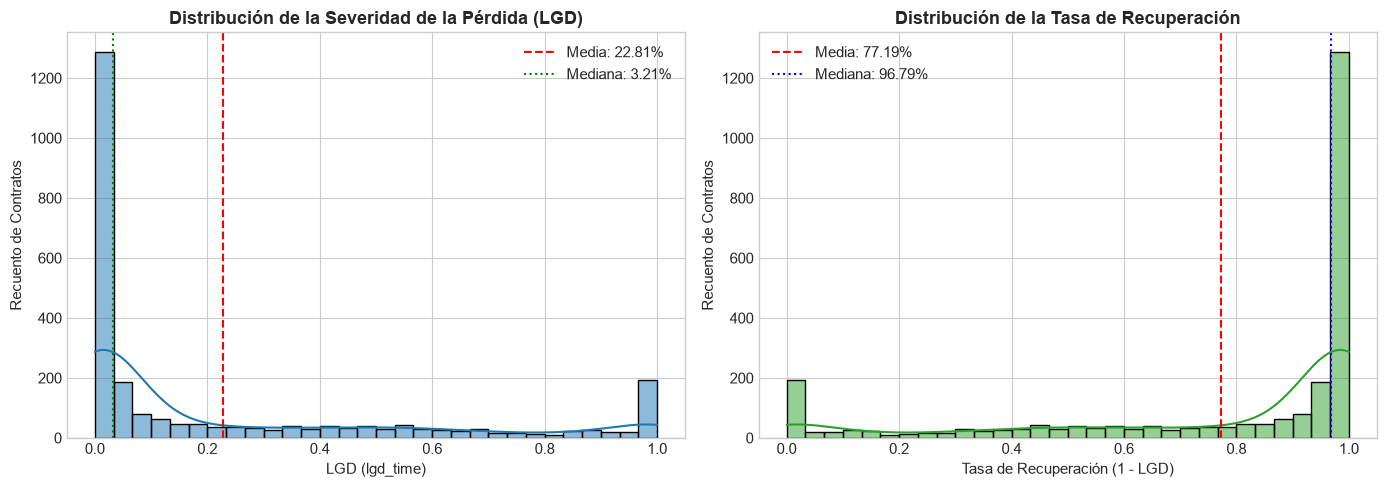

In [5]:
# Distribución de LGD y Tasa de Recuperación
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Distribución de LGD
sns.histplot(df['lgd_time'], bins=30, kde=True, color='#1f77b4', ax=axes[0])
axes[0].set_title("Distribución de la Severidad de la Pérdida (LGD)", fontsize=13, fontweight='bold')
axes[0].set_xlabel("LGD (lgd_time)")
axes[0].set_ylabel("Recuento de Contratos")
axes[0].axvline(df['lgd_time'].mean(), color='red', linestyle='--', label=f"Media: {df['lgd_time'].mean():.2%}")
axes[0].axvline(df['lgd_time'].median(), color='green', linestyle=':', label=f"Mediana: {df['lgd_time'].median():.2%}")
axes[0].legend()

# Distribución de Tasa de Recuperación
sns.histplot(df['Recovery_rate'], bins=30, kde=True, color='#2ca02c', ax=axes[1])
axes[1].set_title("Distribución de la Tasa de Recuperación", fontsize=13, fontweight='bold')
axes[1].set_xlabel("Tasa de Recuperación (1 - LGD)")
axes[1].set_ylabel("Recuento de Contratos")
axes[1].axvline(df['Recovery_rate'].mean(), color='red', linestyle='--', label=f"Media: {df['Recovery_rate'].mean():.2%}")
axes[1].axvline(df['Recovery_rate'].median(), color='blue', linestyle=':', label=f"Mediana: {df['Recovery_rate'].median():.2%}")
axes[1].legend()

plt.tight_layout()
plt.show()

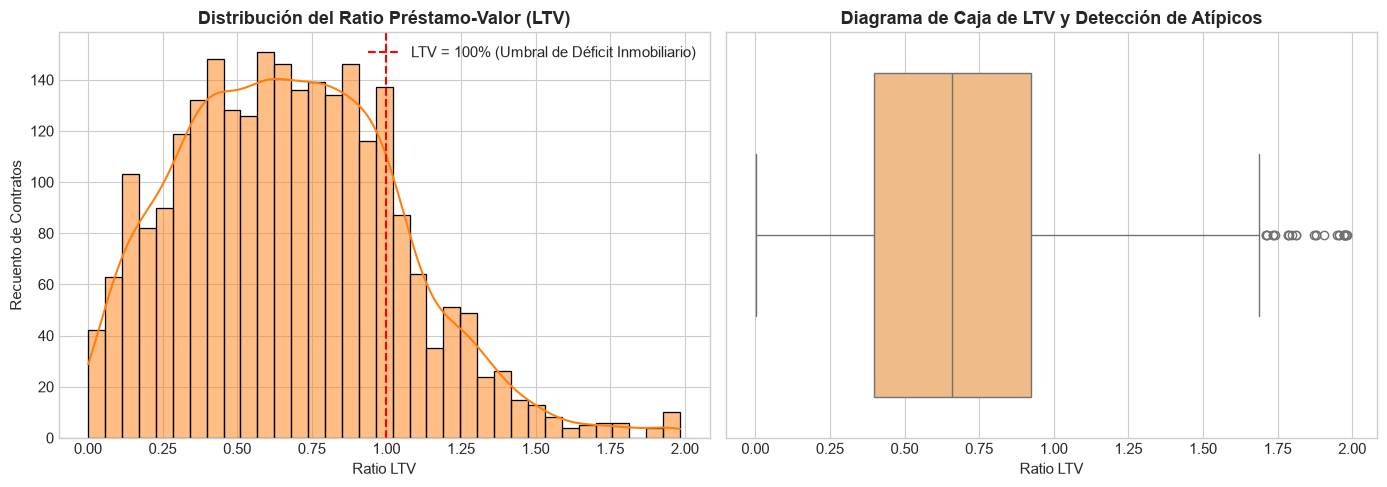

Préstamos en déficit de garantía (LTV > 1.0): 446 (17.52%)


In [6]:
# Análisis de Colateral: Distribución del Ratio Préstamo-Valor (LTV)
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.histplot(df['LTV'], bins=35, kde=True, color='#ff7f0e', ax=axes[0])
axes[0].set_title("Distribución del Ratio Préstamo-Valor (LTV)", fontsize=13, fontweight='bold')
axes[0].set_xlabel("Ratio LTV")
axes[0].set_ylabel("Recuento de Contratos")
axes[0].axvline(1.0, color='red', linestyle='--', label="LTV = 100% (Umbral de Déficit Inmobiliario)")
axes[0].legend()

sns.boxplot(x=df['LTV'], color='#ffbb78', ax=axes[1])
axes[1].set_title("Diagrama de Caja de LTV y Detección de Atípicos", fontsize=13, fontweight='bold')
axes[1].set_xlabel("Ratio LTV")

plt.tight_layout()
plt.show()

underwater = (df['LTV'] > 1.0).sum()
print(f"Préstamos en déficit de garantía (LTV > 1.0): {underwater:,} ({underwater/len(df):.2%})")

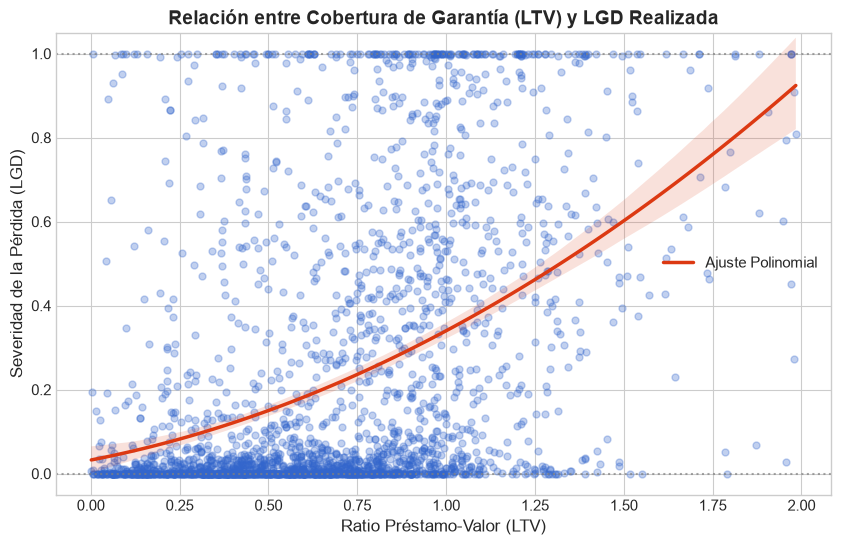

In [7]:
# Relación Bivariada: Cobertura de Garantía (LTV) vs LGD Realizada
fig, ax = plt.subplots(figsize=(10, 6))

sns.regplot(
    data=df, x='LTV', y='lgd_time',
    scatter_kws={'alpha': 0.3, 'color': '#3366cc', 's': 25},
    line_kws={'color': '#dc3912', 'linewidth': 2.5, 'label': 'Ajuste Polinomial'},
    order=2, ax=ax
)
ax.set_title("Relación entre Cobertura de Garantía (LTV) y LGD Realizada", fontsize=14, fontweight='bold')
ax.set_xlabel("Ratio Préstamo-Valor (LTV)", fontsize=12)
ax.set_ylabel("Severidad de la Pérdida (LGD)", fontsize=12)
ax.set_ylim(-0.05, 1.05)
ax.axhline(0.0, color='gray', linestyle=':', alpha=0.7)
ax.axhline(1.0, color='gray', linestyle=':', alpha=0.7)
ax.legend()
plt.show()

C:\Users\jhon_\AppData\Local\Temp\ipykernel_16376\2432566598.py:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(x=df['purpose1'], palette=['#4e79a7', '#e15759'], ax=axes[0])
C:\Users\jhon_\AppData\Local\Temp\ipykernel_16376\2432566598.py:11: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x='purpose1', y='lgd_time', data=df, palette=['#4e79a7', '#e15759'], ax=axes[1])


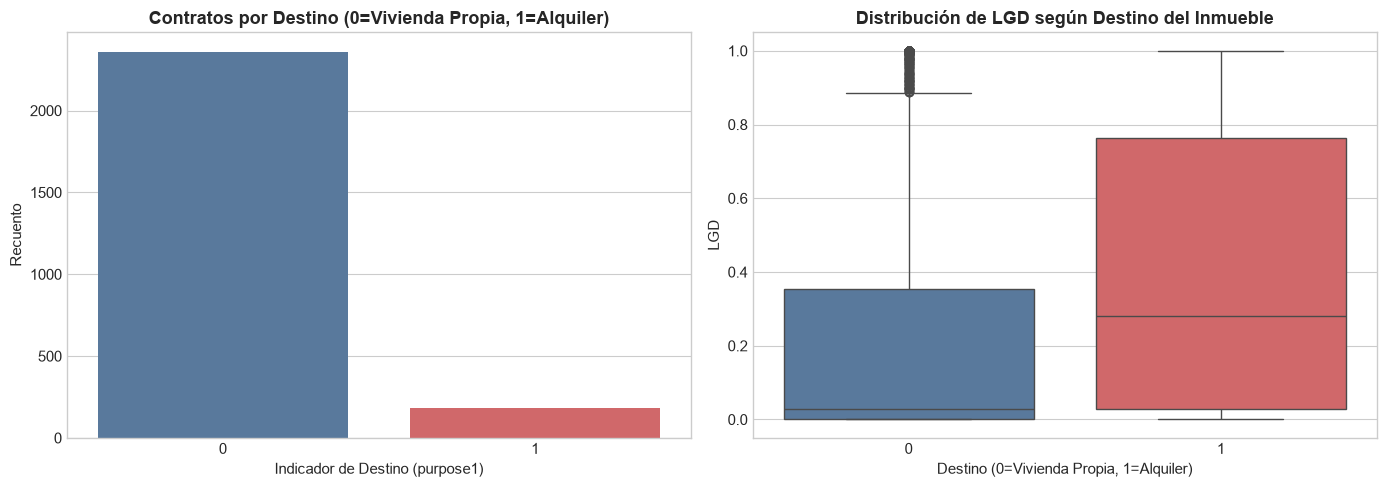

,Recuento,LGD Media,LGD Mediana,Desv Est
purpose1,,,,
0,2360,0.2154,0.0273,0.3215
1,185,0.3907,0.2808,0.3787


In [8]:
# Análisis por Segmento de Destino: Vivienda Propia vs Alquiler (purpose1)
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Recuento por destino
sns.countplot(x=df['purpose1'], palette=['#4e79a7', '#e15759'], ax=axes[0])
axes[0].set_title("Contratos por Destino (0=Vivienda Propia, 1=Alquiler)", fontsize=13, fontweight='bold')
axes[0].set_xlabel("Indicador de Destino (purpose1)")
axes[0].set_ylabel("Recuento")

# LGD por destino
sns.boxplot(x='purpose1', y='lgd_time', data=df, palette=['#4e79a7', '#e15759'], ax=axes[1])
axes[1].set_title("Distribución de LGD según Destino del Inmueble", fontsize=13, fontweight='bold')
axes[1].set_xlabel("Destino (0=Vivienda Propia, 1=Alquiler)")
axes[1].set_ylabel("LGD")

plt.tight_layout()
plt.show()

display(df.groupby('purpose1')['lgd_time'].agg(['count', 'mean', 'median', 'std']).rename(
    columns={'count': 'Recuento', 'mean': 'LGD Media', 'median': 'LGD Mediana', 'std': 'Desv Est'}
).round(4))

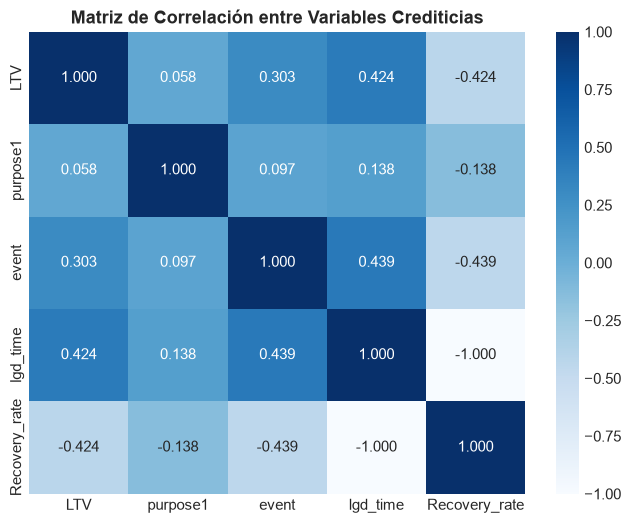

In [9]:
# Matriz de Correlación
corr = df[['LTV', 'purpose1', 'event', 'lgd_time', 'Recovery_rate']].corr()

plt.figure(figsize=(8, 6))
sns.heatmap(corr, annot=True, fmt='.3f', cmap='Blues', vmin=-1, vmax=1, cbar=True)
plt.title("Matriz de Correlación entre Variables Crediticias", fontsize=13, fontweight='bold')
plt.show()

## Conclusiones Clave del EDA y Próximos Pasos

1. **Identidad del Target**: `lgd_time` es idéntica a `1 - Recovery_rate`. Por consiguiente, `Recovery_rate` debe ser excluida estrictamente de los predictores para evitar fuga de información.
2. **Forma de la Distribución**: LGD presenta una masa relevante en 0% (recuperaciones completas o acuerdos judiciales tempranos) y una cola que se extiende hasta el 100%. La mediana (14,5%) es notablemente inferior a la media (31,9%).
3. **Colateral como Predictor Central**: El LTV exhibe una relación positiva estadísticamente significativa con la severidad del quebranto.
4. **Siguiente Cuaderno**: En el Cuaderno 02 delimitamos la población a préstamos en default (`event == 1`) y formalizamos la partición de datos.